In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot  as plt
import seaborn as sns
import statsmodels.api as sm
import itertools
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_percentage_error

sns.set_style("whitegrid")

In [3]:
def fetch_fred(series_id):
    """
    Download a time series from FRED (Federal Reserve Economic Data).
    """
    url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}'

    # Read with utf-8-sig to handle potential BOM characters
    df = pd.read_csv(url, encoding='utf-8-sig')

    # Clean all column names from hidden spaces and make them uppercase
    df.columns = df.columns.str.strip().str.upper()

    # Find the date column dynamically (usually the first column)
    date_col = df.columns[0]

    # Convert the date column to datetime and set it as the index
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.set_index(date_col)

    # Rename the remaining data column to match the series ID
    df.columns = [series_id]

    return df

In [4]:
# Fetch three macroeconomic series from FRED
# DRCLACBS: Delinquency rate on consumer loans (used as a proxy for PD)
# UNRATE: US unemployment rate
# A191RL1Q225SBEA: Real GDP growth

delinq = fetch_fred("DRCLACBS")
unrate = fetch_fred("UNRATE")
gdp = fetch_fred("A191RL1Q225SBEA")

# Combine into a single DataFrame
df = delinq.join(unrate, how="outer").join(gdp, how="outer")
df.columns = ["delinq", "unrate", "gdp_growth"]

# Interpolate to fill any missing values, which SARIMA requires
df_q = df.resample("QE").mean().interpolate()

# Drop any remaining missing values (e.g. at the start of the series)
df_q = df_q.dropna()

# Inspect the first and last rows to verify data intergrity
print(df_q.head())
print(df_q.tail())

                  delinq    unrate  gdp_growth
OBSERVATION_DATE                              
1987-03-31          3.35  6.600000         3.0
1987-06-30          3.28  6.266667         4.4
1987-09-30          3.29  6.000000         3.5
1987-12-31          3.31  5.833333         7.0
1988-03-31          3.27  5.700000         2.1
                  delinq    unrate  gdp_growth
OBSERVATION_DATE                              
2025-09-30          2.72  4.333333         3.9
2025-12-31          2.63  4.450000         0.2
2026-03-31          2.64  4.333333         2.5
2026-06-30          2.62  4.266667         2.2
2026-09-30          2.62  4.133333         2.2


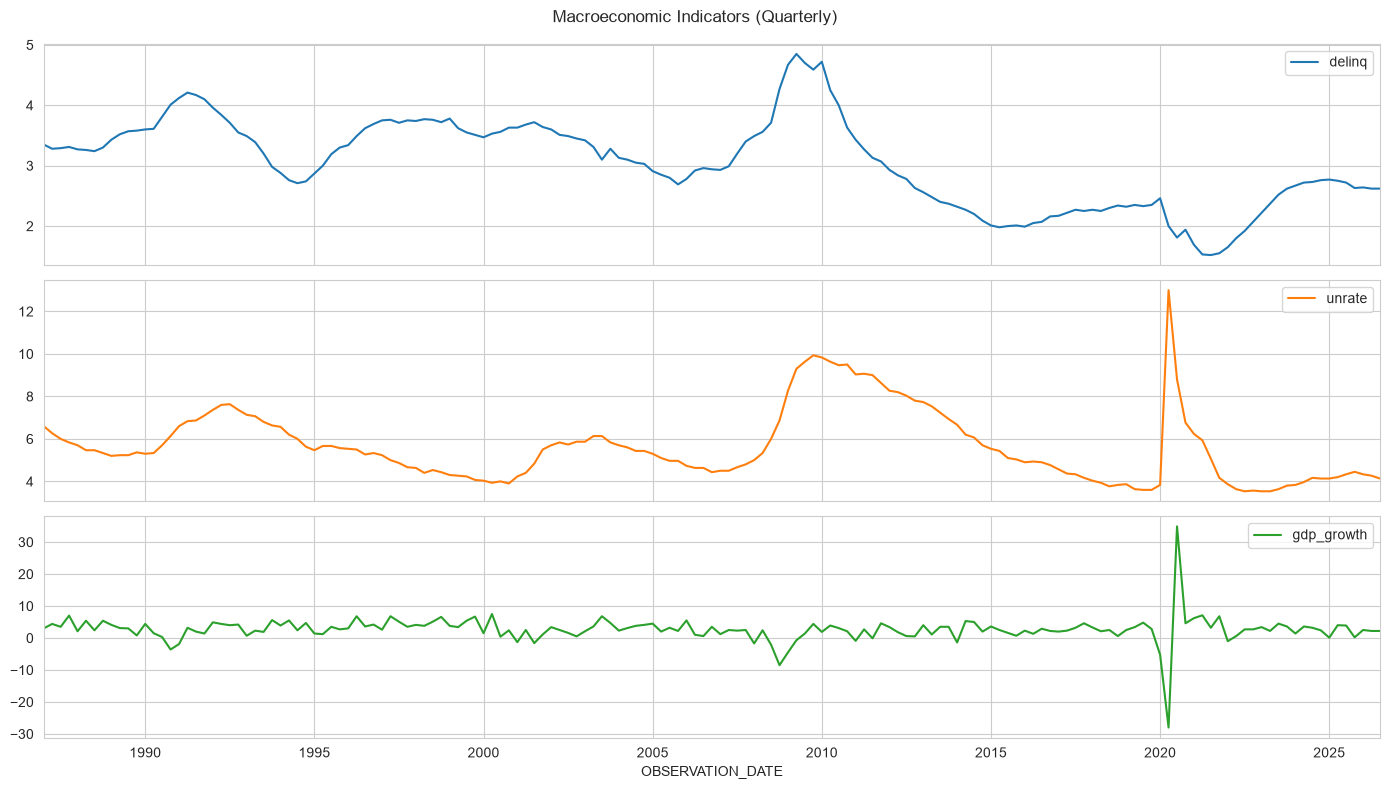

In [5]:
# Plot each seires in a separate subplot for visual inspection
# Look for overall trends, sudden structural breaks, and volatility clustering
df_q.plot(figsize=(14, 8), subplots=True, title="Macroeconomic Indicators (Quarterly)")

# Adjust the layout to prevent overlapping labels and add spacing
plt.tight_layout()

# Display the plots
plt.show()

In [6]:
def adf_test(series, name):
    """
    Run Augmented Dickey-Fuller test to check for stationarity.
    H0 (Null Hypothesis): The series has a unit root (is non-stationary).
    If p-value < 0.05, we reject H0 and conclude the series is stationary.
    """
    # Drop NaNs to prevent errors, though we already cleaned the data
    result = adfuller(series.dropna(), autolag='AIC')

    print(f'--- ADF Test: {name} ---')
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value:       {result[1]:.4f}')

    # Print critical values to compare against the test statistic
    for key, value in result[4].items():
        print(f'Critical Value ({key}): {value:.4f}')

    # Interpret the result
    if result[1] < 0.05:
        print("=> Reject H0: The series is STATIONARY.\n")
    else:
        print("=> Fail to reject H0: The series is NON-STATIONARY (has a trend).\n")

# Test the original delinquency series
adf_test(df_q['delinq'], 'Delinquency Rate (Original)')

# Test the differenced delinquency series (y_t - y_{t-1})
# We use .diff() to remove the trend
adf_test(df_q['delinq'].diff(), 'Delinquency Rate (Differenced)')

--- ADF Test: Delinquency Rate (Original) ---
ADF Statistic: -2.1909
p-value:       0.2096
Critical Value (1%): -3.4741
Critical Value (5%): -2.8807
Critical Value (10%): -2.5770
=> Fail to reject H0: The series is NON-STATIONARY (has a trend).

--- ADF Test: Delinquency Rate (Differenced) ---
ADF Statistic: -5.0778
p-value:       0.0000
Critical Value (1%): -3.4747
Critical Value (5%): -2.8810
Critical Value (10%): -2.5772
=> Reject H0: The series is STATIONARY.



C:\Users\Hem\AppData\Local\Temp\ipykernel_11608\260203900.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')
C:\Users\Hem\AppData\Local\Temp\ipykernel_11608\260203900.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')


In [7]:
# Define the range of paramters of test
# p, d, q: non-seasonal AR, Differencing, MA orders
# P, D, Q: seasonal AR, Differencing, MA orders
p = d = q = range(0, 3) # Tests 0, 1, 2
seasonal_pdq = [(x[0], x[1], x[2], 4) for x in itertools.product(p, d, q)]

# Initialize variables to keep track of the best model
best_aic = np.inf
best_order = None
best_seasonal = None

print("Starting Grid Search... (this may take a minute)")

# Loop through all combinations
for order in itertools.product(p, d, q):
    for seasonal_order in seasonal_pdq:
        try:
            # Build and fit the SARIMA model
            model = SARIMAX(df_q['delinq'],
                            order=order,
                            seasonal_order=seasonal_order,
                            enforce_stationarity=False,
                            enforce_invertibility=False)
            results = model.fit(disp=False)

            # Check if this model has a lower AIC (better) than the current best
            if results.aic < best_aic:
                best_aic = results.aic
                best_order = order
                best_seasonal = seasonal_order

        except Exception as e:
            # If a specific combination fails to converge, skip it
            continue

print(f"Best SARIMA Model Found:")
print(f"Non-seasonal order (p, d, q): {best_order}")
print(f"Seasonal order (P, D, Q, s): {best_seasonal}")
print(f"AIC Score: {best_aic:.2f}")

Starting Grid Search... (this may take a minute)


c:\Users\Hem\projects\credit-risk\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Hem\projects\credit-risk\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Hem\projects\credit-risk\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Hem\projects\credit-risk\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Hem\projects\credit-risk\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likeli

Best SARIMA Model Found:
Non-seasonal order (p, d, q): (2, 0, 1)
Seasonal order (P, D, Q, s): (0, 0, 0, 4)
AIC Score: -249.36


c:\Users\Hem\projects\credit-risk\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


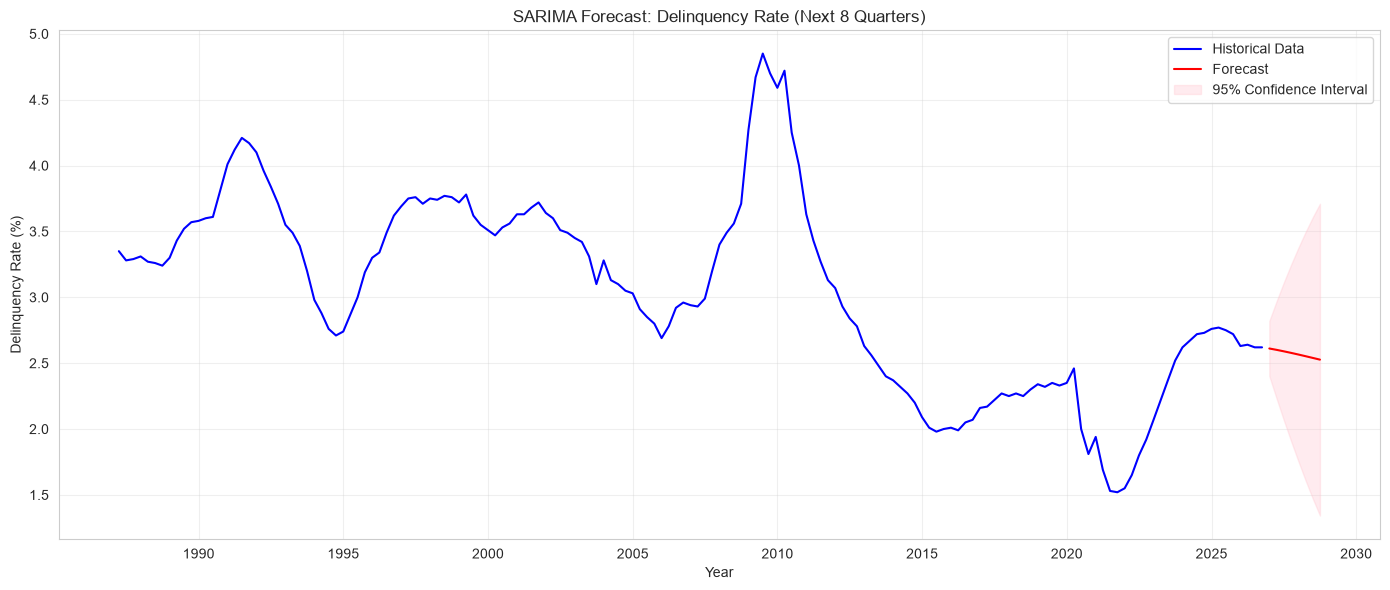

In [8]:
# Build the final SARIMA model using the best parameters found
final_model = SARIMAX(df_q['delinq'],
                      order=(2, 0, 1),
                      seasonal_order=(0, 0, 0, 4),
                      enforce_stationarity=False,
                      enforce_invertibility=False)

# Fit the model to the data
final_results = final_model.fit(disp=False)

# Generate a forecast for the next 8 quarters (2 years)
forecast = final_results.get_forecast(steps=8)

# Extract the predicted mean and the 95% confidence interval
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

# Create the plot
plt.figure(figsize=(14, 6))

# Plot historical data in blue
plt.plot(df_q.index, df_q['delinq'], label='Historical Data', color='blue')

# Plot the forecast in red
plt.plot(forecast_mean.index, forecast_mean, label='Forecast', color='red')

# Plot the confidence interval as a shaded area
plt.fill_between(forecast_ci.index,
                 forecast_ci.iloc[:, 0],
                 forecast_ci.iloc[:, 1],
                 color='pink', alpha=0.3, label='95% Confidence Interval')

# Formatting
plt.title('SARIMA Forecast: Delinquency Rate (Next 8 Quarters)')
plt.xlabel('Year')
plt.ylabel('Delinquency Rate (%)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Mean Absolute Percentage Error (MAPE): 2.03%


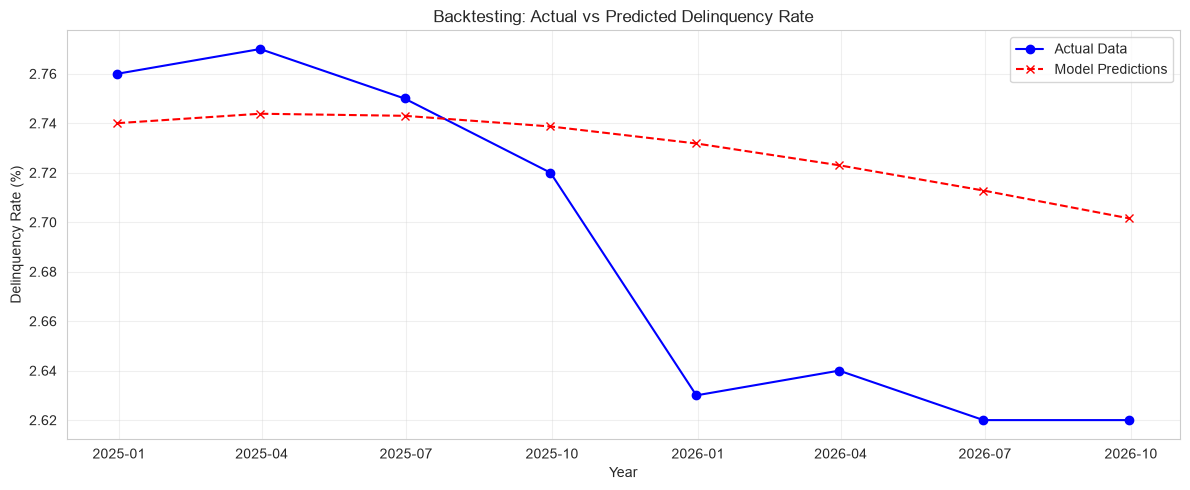

In [10]:
# Split the data: train on all but the last 8 quarters, test on the last 8
train = df_q['delinq'][:-8]
test = df_q['delinq'][-8:]

# Build and fit the model on the training data only
# We use the same parameters that won the grid search
model_train = SARIMAX(train,
                      order=(2, 0, 1),
                      seasonal_order=(0, 0, 0, 4),
                      enforce_stationarity=False,
                      enforce_invertibility=False)
results_train = model_train.fit(disp=False)

# Forecast the test period (8 quarters)
predictions = results_train.get_forecast(steps=8).predicted_mean

# Calculate MAPE (Mean Absolute Percentage Error)
mape = mean_absolute_percentage_error(test, predictions) * 100

print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

# Create a plot to visually compare actuals vs predictions
plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label='Actual Data', marker='o', color='blue')
plt.plot(test.index, predictions, label='Model Predictions', marker='x', color='red', linestyle='--')
plt.title('Backtesting: Actual vs Predicted Delinquency Rate')
plt.xlabel('Year')
plt.ylabel('Delinquency Rate (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Add a constant (intercept) to the independent variables
# statsmodels requires this to be done explicitly
X = sm.add_constant(df_q[['unrate', 'gdp_growth']])
y = df_q['delinq']

# Fit the OLS (Ordinary Least Squares) regression model
ols_model = sm.OLS(y, X).fit()

# Print the full statistical summary
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 delinq   R-squared:                       0.121
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     10.71
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           4.37e-05
Time:                        19:07:30   Log-Likelihood:                -163.04
No. Observations:                 159   AIC:                             332.1
Df Residuals:                     156   BIC:                             341.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.2348      0.202     11.060      0.0

Base       | PD: 2.83% | EL: 1.27
Adverse    | PD: 3.13% | EL: 1.41
Severe     | PD: 3.43% | EL: 1.55


C:\Users\Hem\AppData\Local\Temp\ipykernel_11608\2262135705.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Scenario', y='EL', data=df_results, palette='Reds')


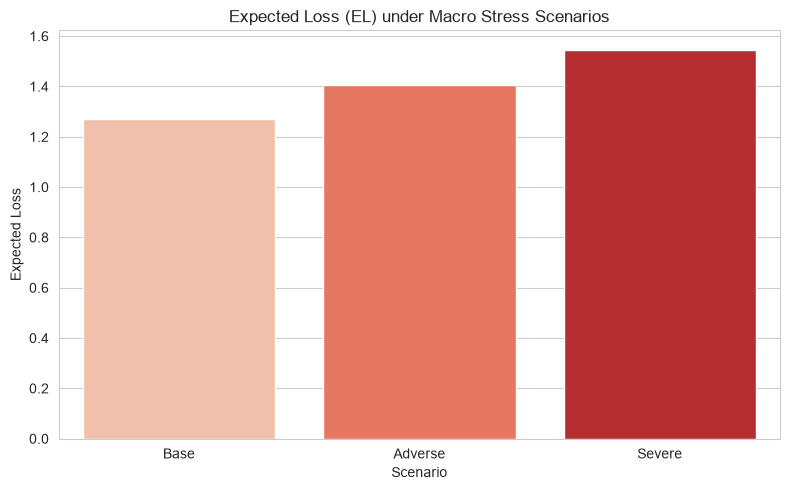

In [12]:
# Get the latest macroeconomic values to use as our baseline
last_unrate = df_q['unrate'].iloc[-1]
last_gdp = df_q['gdp_growth'].iloc[-1]

# Define three macroeconomic scenarios
# Base: Current conditions
# Adverse: Unemployment +2pp, GDP -1pp
# Severe: Unemployment +4pp, GDP -3pp
scenarios = {
    'Base': {'const': 1, 'unrate': last_unrate, 'gdp_growth': last_gdp},
    'Adverse': {'const': 1, 'unrate': last_unrate + 2, 'gdp_growth': last_gdp - 1},
    'Severe': {'const': 1, 'unrate': last_unrate + 4, 'gdp_growth': last_gdp - 3}
}

# Assumptions for Expected Loss
LGD = 0.45 # 45% loss given default
EAD = 100  # Normalized exposure

results_list = []

# Loop through scenarios and calculate Expected Loss (EL)
for name, scenario in scenarios.items():
    # Convert scenario to a DataFrame to predict PD
    X_scenario = pd.DataFrame([scenario])

    # Predict PD (delinquency rate) under this scenario
    predicted_pd = ols_model.predict(X_scenario)[0]

    # Calculate Expected Loss (EL = PD * LGD * EAD)
    # Divide predicted_pd by 100 because it is in percentage
    expected_loss = (predicted_pd / 100) * LGD * EAD

    results_list.append({'Scenario': name, 'PD (%)': predicted_pd, 'EL': expected_loss})
    print(f"{name:10} | PD: {predicted_pd:.2f}% | EL: {expected_loss:.2f}")

# Create a bar chart for the Expected Loss across scenarios
df_results = pd.DataFrame(results_list)

plt.figure(figsize=(8, 5))
sns.barplot(x='Scenario', y='EL', data=df_results, palette='Reds')
plt.title('Expected Loss (EL) under Macro Stress Scenarios')
plt.ylabel('Expected Loss')
plt.xlabel('Scenario')
plt.tight_layout()
plt.show()

--- Ljung-Box Test ---
    lb_stat  lb_pvalue
8  32.51269   0.000075




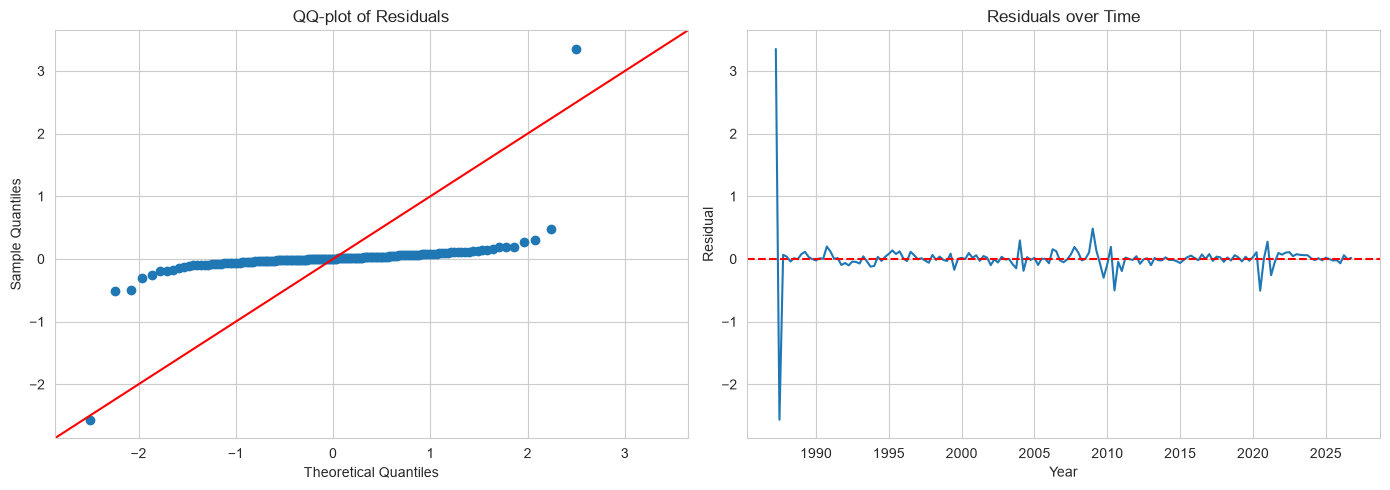

In [13]:
# Extract residuals from our final SARIMA model
residuals = final_results.resid

# 1. Ljung-Box Test
# H0: Residuals are independently distributed (white noise)
lb_test = acorr_ljungbox(residuals, lags=[8], return_df=True)
print("--- Ljung-Box Test ---")
print(lb_test)
print("\n")

# 2. Visual Diagnostics (QQ-plot and Residuals over time)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# QQ-plot: Checks if residuals are normally distributed
sm.qqplot(residuals, line='45', ax=ax[0])
ax[0].set_title('QQ-plot of Residuals')
ax[0].set_xlabel('Theoretical Quantiles')
ax[0].set_ylabel('Sample Quantiles')

# Residuals over time: Checks for constant variance and no trends
ax[1].plot(residuals)
ax[1].axhline(0, color='red', linestyle='--') # Add a zero line for reference
ax[1].set_title('Residuals over Time')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('Residual')

plt.tight_layout()
plt.show()

## Conclusions and Model Limitations

This project successfully developed a quantitative framework for forecasting consumer credit risk (delinquency rate as a PD proxy) and performing macroeconomic stress testing.

### Key Findings:
1. **Time Series Modeling:** The SARIMA(2,0,1)(0,0,0,4) model achieved an out-of-sample MAPE of ~2.03%, demonstrating high accuracy in predicting normal cyclical fluctuations in credit risk.
2. **Macroeconomic Linkage:** OLS regression confirmed a statistically significant positive relationship between unemployment and delinquency rates. A 1pp increase in unemployment correlates with a ~0.15pp increase in delinquency.
3. **Stress Testing:** Under a severe scenario (Unemployment +4pp, GDP -3pp), the Expected Loss (EL) increases by approximately 22% compared to the baseline scenario.

### Model Limitations (Model Validation):
- **Ljung-Box Test:** The residual diagnostics yielded a p-value < 0.05, rejecting the null hypothesis of white noise. This indicates that the SARIMA model struggles to capture extreme structural breaks (e.g., the 2008 Financial Crisis and the 2020 COVID-19 shock).
- **Fat Tails:** The QQ-plot reveals heavy tails in the residuals, implying that extreme events occur more frequently than a normal distribution would predict.
- **Regression R-squared:** The OLS model explains ~12% of the variance, highlighting that macroeconomic factors are only one piece of the puzzle; bank-specific policies and regulatory interventions also play a major role.

**Final Thought:** While the time-series model is excellent for baseline forecasting, the limitations revealed by the residual diagnostics justify the necessity of forward-looking scenario analysis and stress testing (aligned with IFRS 9 requirements) to ensure adequate capital buffers during extreme market conditions.